# Análise Macroeconômica de Valória
## Inferência Estatística e Análise de Dados — Projeto em Python

**Objetivo:** explorar os indicadores macroeconômicos simulados de Valória, investigar diferenças entre grupos e estimar modelos de regressão para compreender associações entre crescimento do PIB, inflação, juros, desemprego e investimento estrangeiro.

**Metodologia:** leitura e preparação dos dados, análise exploratória, visualizações, testes de hipóteses paramétricos e não paramétricos, ANOVAs, modelos de regressão e elaboração de um informe executivo com conclusões orientadas por evidências.

> **Limitação importante:** Valória é fictícia e a base é simulada. Os resultados descrevem somente o conjunto de dados fornecido e não devem ser interpretados como evidência sobre um país real. Associação estatística não comprova causalidade.


## 1. Bibliotecas e configuração

O notebook usa bibliotecas para manipulação de dados, visualização, testes de hipóteses e regressão. Caso necessário, instale as dependências no Google Colab.


In [2]:
# Se estiver no Google Colab e alguma biblioteca não estiver disponível, execute:
# %pip install pandas numpy scipy statsmodels seaborn matplotlib scikit-learn openpyxl

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
ALFA = 0.05

In [3]:
from pathlib import Path

arquivo = Path("dados_macroeconomicos_valoria.xlsx")
if not arquivo.exists():
    try:
        from google.colab import files
        enviados = files.upload()
        arquivo = Path(next(iter(enviados.keys())))
    except ImportError:
        raise FileNotFoundError(
            "Coloque o arquivo dados_macroeconomicos_valoria.xlsx na pasta do notebook."
        )

df = pd.read_excel(arquivo)

print(f"Dimensões: {df.shape[0]} linhas e {df.shape[1]} colunas")
display(df.head())
print("\nTipos de dados:")
display(df.dtypes.to_frame("Tipo"))
print("\nValores ausentes por coluna:")
display(df.isna().sum().to_frame("Valores ausentes"))
print("\nQuantidade de linhas duplicadas:", df.duplicated().sum())


Dimensões: 100 linhas e 10 colunas


,ID,Ano,Regiao,Orientacao_Politica,Crescimento_PIB_Pct,Inflacao_Pct,Taxa_Juros_Selic,Desemprego_Pct,Investimento_Estrangeiro_Milhoes,Indice_Confianca_Consumidor
0,1,2000,Sul,Desenvolvimentista,-1.410,3.680,12.240,13.710,294.750,1
1,2,2000,Oeste,Liberal,-0.100,4.780,10.060,12.210,130.590,3
2,3,2000,Leste,Desenvolvimentista,1.320,4.850,4.960,11.120,146.170,2
3,4,2000,Leste,Liberal,-0.400,3.640,7.030,12.110,66.550,5
4,5,2001,Norte,Liberal,-0.430,6.740,10.530,12.100,146.230,2



Tipos de dados:


,Tipo
ID,int64
Ano,int64
Regiao,str
Orientacao_Politica,str
Crescimento_PIB_Pct,float64
Inflacao_Pct,float64
Taxa_Juros_Selic,float64
Desemprego_Pct,float64
Investimento_Estrangeiro_Milhoes,float64
Indice_Confianca_Consumidor,int64



Valores ausentes por coluna:


,Valores ausentes
ID,0
Ano,0
Regiao,0
Orientacao_Politica,0
Crescimento_PIB_Pct,0
Inflacao_Pct,0
Taxa_Juros_Selic,0
Desemprego_Pct,0
Investimento_Estrangeiro_Milhoes,0
Indice_Confianca_Consumidor,0



Quantidade de linhas duplicadas: 0


## 3. Preparação e qualidade dos dados

As colunas reais do arquivo são utilizadas diretamente. O identificador `ID` não é tratado como variável explicativa. A coluna `Ano` é temporal; as variáveis categóricas são `Regiao` e `Orientacao_Politica`.

A base fornecida possui 100 registros e as seguintes variáveis de interesse: crescimento do PIB, inflação, taxa de juros, desemprego, investimento estrangeiro e índice de confiança do consumidor. Antes de interpretar os resultados, verificamos ausências, duplicidades e valores inválidos.


In [4]:
colunas_numericas = [
    "Crescimento_PIB_Pct",
    "Inflacao_Pct",
    "Taxa_Juros_Selic",
    "Desemprego_Pct",
    "Investimento_Estrangeiro_Milhoes",
    "Indice_Confianca_Consumidor"
]
colunas_categoricas = ["Regiao", "Orientacao_Politica"]

# Conversão defensiva das variáveis numéricas
for coluna in colunas_numericas:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

print("Valores ausentes após conversão:")
display(df.isna().sum().to_frame("Ausentes"))

# Remoção de linhas duplicadas exatas, se houver
df = df.drop_duplicates().copy()

# Remover apenas linhas sem valores nas variáveis que serão analisadas
variaveis_analise = colunas_numericas + colunas_categoricas
dados = df.dropna(subset=variaveis_analise).copy()

print(f"Registros após limpeza: {len(dados)}")
print("Categorias de região:", sorted(dados["Regiao"].unique()))
print("Categorias de orientação política:", sorted(dados["Orientacao_Politica"].unique()))


Valores ausentes após conversão:


,Ausentes
ID,0
Ano,0
Regiao,0
Orientacao_Politica,0
Crescimento_PIB_Pct,0
Inflacao_Pct,0
Taxa_Juros_Selic,0
Desemprego_Pct,0
Investimento_Estrangeiro_Milhoes,0
Indice_Confianca_Consumidor,0


Registros após limpeza: 100
Categorias de região: ['Leste', 'Norte', 'Oeste', 'Sul']
Categorias de orientação política: ['Desenvolvimentista', 'Liberal']


## 4. Análise exploratória e estatística descritiva

Calculamos média, mediana, desvio-padrão, variância, quartis, amplitude interquartil (IQR), mínimo, máximo, assimetria e curtose. Essas medidas ajudam a entender o centro, a dispersão e o formato das distribuições antes dos testes inferenciais.


In [5]:
def resumo_estatistico(serie):
    serie = serie.dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    return pd.Series({
        "Média": serie.mean(),
        "Mediana": serie.median(),
        "Desvio-padrão": serie.std(),
        "Variância": serie.var(),
        "Q1": q1,
        "Q3": q3,
        "IQR": q3 - q1,
        "Mínimo": serie.min(),
        "Máximo": serie.max(),
        "Assimetria": serie.skew(),
        "Curtose": serie.kurt()
    })

tabela_descritiva = pd.DataFrame({
    coluna: resumo_estatistico(dados[coluna])
    for coluna in colunas_numericas
}).T
display(tabela_descritiva.round(3))


,Média,Mediana,Desvio-padrão,Variância,Q1,Q3,IQR,Mínimo,Máximo,Assimetria,Curtose
Crescimento_PIB_Pct,0.285,0.190,1.102,1.215,-0.405,1.092,1.498,-1.910,2.740,0.173,-0.429
Inflacao_Pct,4.630,4.715,1.207,1.456,3.640,5.320,1.680,2.070,9.120,0.603,1.227
Taxa_Juros_Selic,8.053,8.090,1.868,3.490,6.815,9.275,2.460,1.520,12.270,-0.210,0.661
Desemprego_Pct,11.802,11.800,1.051,1.104,11.070,12.593,1.523,9.040,14.200,-0.173,-0.183
Investimento_Estrangeiro_Milhoes,214.109,152.725,181.556,"32,962.693",81.378,262.560,181.182,27.140,855.630,1.656,2.603
Indice_Confianca_Consumidor,2.720,3.000,1.092,1.194,2.000,3.000,1.000,1.000,5.000,0.201,-0.544


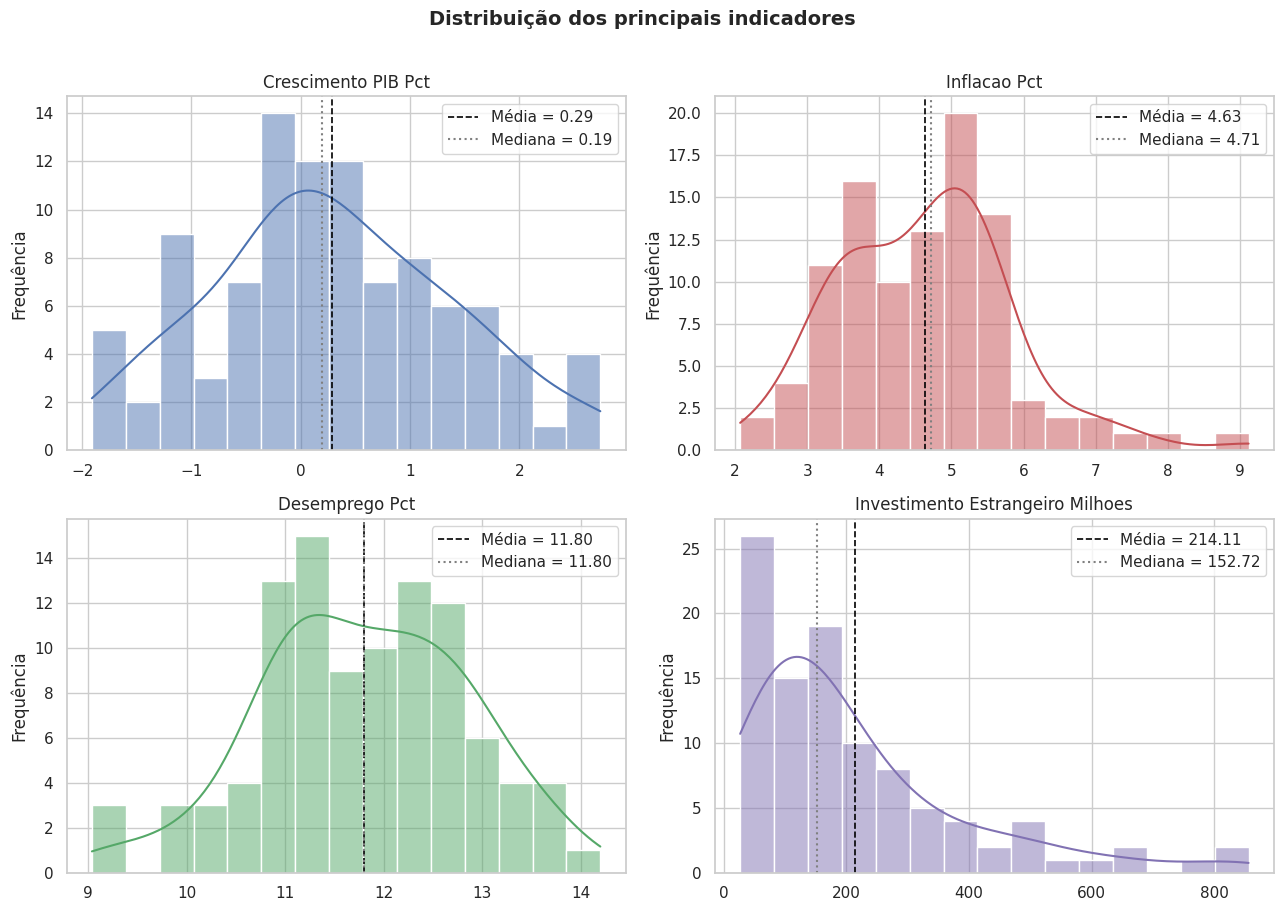

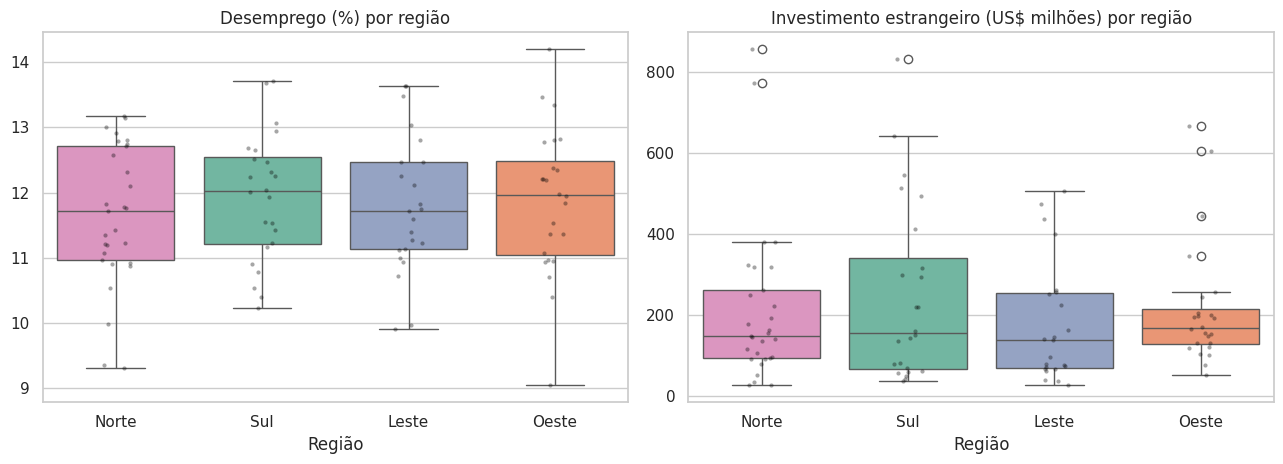

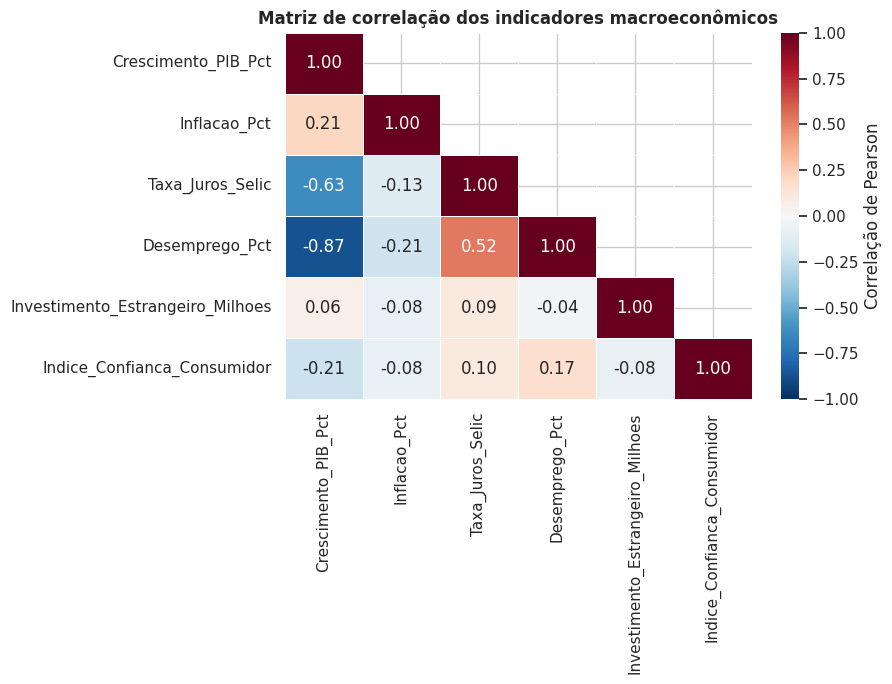

In [6]:
# Gráfico 1 — Histogramas com KDE (média e mediana destacadas)
variaveis_graficos = ["Crescimento_PIB_Pct", "Inflacao_Pct", "Desemprego_Pct", "Investimento_Estrangeiro_Milhoes"]
cores = ["#4c72b0", "#c44e52", "#55a868", "#8172b3"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, coluna, cor in zip(axes.ravel(), variaveis_graficos, cores):
    sns.histplot(dados[coluna], kde=True, bins=15, color=cor, edgecolor="white", ax=ax)
    ax.axvline(dados[coluna].mean(), color="black", ls="--", lw=1.2, label=f"Média = {dados[coluna].mean():.2f}")
    ax.axvline(dados[coluna].median(), color="gray", ls=":", lw=1.5, label=f"Mediana = {dados[coluna].median():.2f}")
    ax.set_title(coluna.replace("_", " "))
    ax.set_xlabel(""); ax.set_ylabel("Frequência"); ax.legend()
plt.suptitle("Distribuição dos principais indicadores", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Gráfico 2 — Boxplots por região (desemprego e investimento estrangeiro)
ordem_regioes = ["Norte", "Sul", "Leste", "Oeste"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, coluna, titulo in zip(axes, ["Desemprego_Pct", "Investimento_Estrangeiro_Milhoes"],
                              ["Desemprego (%) por região", "Investimento estrangeiro (US$ milhões) por região"]):
    sns.boxplot(data=dados, x="Regiao", y=coluna, order=ordem_regioes, hue="Regiao",
                palette="Set2", legend=False, ax=ax)
    sns.stripplot(data=dados, x="Regiao", y=coluna, order=ordem_regioes,
                  color="black", alpha=.35, size=3, ax=ax)
    ax.set_title(titulo); ax.set_xlabel("Região"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Gráfico 3 — Heatmap da matriz de correlação (triângulo inferior)
corr = dados[colunas_numericas].corr(numeric_only=True)
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.5, cbar_kws={"label": "Correlação de Pearson"})
plt.title("Matriz de correlação dos indicadores macroeconômicos", fontweight="bold")
plt.tight_layout()
plt.show()

### Como interpretar esta etapa

- A média e a mediana ajudam a identificar possíveis assimetrias.
- O desvio-padrão e o IQR mostram a dispersão dos indicadores.
- Histogramas e boxplots ajudam a observar formato, concentração e valores extremos.
- A correlação mede associação linear, mas não demonstra que uma variável causa outra.



### 4.1 Os indicadores têm tendência ao longo dos anos?

Para sustentar (ou descartar) afirmações sobre tendência temporal, testamos a correlação de cada indicador com `Ano`.

- **H₀:** não há correlação entre o indicador e o ano (ρ = 0).
- **H₁:** há correlação entre o indicador e o ano (ρ ≠ 0).


In [7]:
tendencia = []
for coluna in colunas_numericas:
    r, p_r = stats.pearsonr(dados["Ano"], dados[coluna])
    rho, p_rho = stats.spearmanr(dados["Ano"], dados[coluna])
    tendencia.append({
        "Indicador": coluna,
        "r de Pearson": round(r, 3), "p (Pearson)": round(p_r, 4),
        "rho de Spearman": round(rho, 3), "p (Spearman)": round(p_rho, 4),
        "Decisão (5%)": "Rejeitar H₀" if p_r < ALFA else "Não rejeitar H₀"
    })
print(pd.DataFrame(tendencia).to_string(index=False))


                       Indicador  r de Pearson  p (Pearson)  rho de Spearman  p (Spearman)    Decisão (5%)
             Crescimento_PIB_Pct        -0.102       0.3132           -0.085        0.4029 Não rejeitar H₀
                    Inflacao_Pct        -0.066       0.5152           -0.056        0.5823 Não rejeitar H₀
                Taxa_Juros_Selic         0.013       0.8981           -0.005        0.9588 Não rejeitar H₀
                  Desemprego_Pct         0.070       0.4883            0.089        0.3782 Não rejeitar H₀
Investimento_Estrangeiro_Milhoes        -0.042       0.6808           -0.070        0.4861 Não rejeitar H₀
     Indice_Confianca_Consumidor         0.083       0.4121            0.079        0.4320 Não rejeitar H₀


## 5. Testes de normalidade e aderência

### 5.1 Shapiro–Wilk

Para cada variável, as hipóteses são:

- **H₀:** os dados são compatíveis com uma distribuição normal.
- **H₁:** os dados não são compatíveis com uma distribuição normal.

Com nível de significância de 5%, rejeitamos H₀ quando o p-valor é menor que 0,05. O teste deve ser interpretado junto com os histogramas e o tamanho da amostra.


In [8]:
def interpretar_p(p, alfa=ALFA):
    return "Rejeitar H₀" if p < alfa else "Não rejeitar H₀"

resultados_shapiro = []
for coluna in ["Crescimento_PIB_Pct", "Inflacao_Pct"]:
    valores = dados[coluna].dropna()
    estatistica, p = stats.shapiro(valores)
    resultados_shapiro.append({
        "Variável": coluna,
        "Estatística W": estatistica,
        "p-valor": p,
        "Decisão (5%)": interpretar_p(p)
    })

display(pd.DataFrame(resultados_shapiro).round(5))


,Variável,Estatística W,p-valor,Decisão (5%)
0,Crescimento_PIB_Pct,0.986,0.358,Não rejeitar H₀
1,Inflacao_Pct,0.969,0.019,Rejeitar H₀


### 5.2 Qui-quadrado de aderência entre regiões

- **H₀:** as observações estão distribuídas igualmente entre as regiões presentes na base.
- **H₁:** a distribuição das observações entre as regiões não é uniforme.

O teste compara as frequências observadas com frequências esperadas iguais. Ele avalia a composição desta amostra; não prova que as regiões tenham o mesmo tamanho populacional.


In [9]:
frequencias = dados["Regiao"].value_counts().sort_index()
esperadas = np.repeat(frequencias.sum() / len(frequencias), len(frequencias))
chi2, p_chi = stats.chisquare(f_obs=frequencias.values, f_exp=esperadas)

display(pd.DataFrame({
    "Frequência observada": frequencias,
    "Frequência esperada": esperadas
}))
print(f"Qui-quadrado = {chi2:.4f} | p-valor = {p_chi:.5f}")
print("Decisão:", interpretar_p(p_chi))


,Frequência observada,Frequência esperada
Regiao,,
Leste,23,25.000
Norte,29,25.000
Oeste,24,25.000
Sul,24,25.000


Qui-quadrado = 0.8800 | p-valor = 0.83025
Decisão: Não rejeitar H₀


## 6. Testes de hipóteses para dois grupos

### 6.1 Homogeneidade de variâncias (Levene) e teste t

Comparamos o crescimento do PIB entre as categorias de `Orientacao_Politica`.

**Levene**
- H₀: as variâncias do crescimento do PIB são iguais entre os grupos.
- H₁: as variâncias são diferentes.

**Teste t de Student para amostras independentes**
- H₀: as médias do crescimento do PIB são iguais entre os grupos.
- H₁: as médias são diferentes.

A base fornecida não possui a variável `Periodo_Politica`; usamos `Orientacao_Politica` (Desenvolvimentista × Liberal), que é a variável binária de política disponível. Como o teste de Levene não rejeita a igualdade de variâncias, aplica-se o teste t de Student clássico (variâncias iguais, `equal_var=True`). O resultado é uma comparação observacional entre grupos, não uma prova causal do efeito da orientação política.


In [10]:
grupos_politica = [
    dados.loc[dados["Orientacao_Politica"] == categoria, "Crescimento_PIB_Pct"].dropna()
    for categoria in sorted(dados["Orientacao_Politica"].unique())
]
nomes_politica = sorted(dados["Orientacao_Politica"].unique())

if len(grupos_politica) == 2 and all(len(g) > 0 for g in grupos_politica):
    lev_stat, lev_p = stats.levene(*grupos_politica, center="median")
    t_stat, t_p = stats.ttest_ind(*grupos_politica, equal_var=True)
    print("Médias por orientação política:")
    display(dados.groupby("Orientacao_Politica")["Crescimento_PIB_Pct"].agg(["count", "mean", "std"]))
    print(f"Levene: estatística={lev_stat:.4f}, p-valor={lev_p:.5f}, decisão={interpretar_p(lev_p)}")
    print(f"Teste t de Student: t={t_stat:.4f}, p-valor={t_p:.5f}, decisão={interpretar_p(t_p)}")
else:
    print("Não foi possível comparar: a base não contém exatamente dois grupos válidos.")


Médias por orientação política:


,count,mean,std
Orientacao_Politica,,,
Desenvolvimentista,49,0.672,1.041
Liberal,51,-0.087,1.038


Levene: estatística=0.0107, p-valor=0.91783, decisão=Não rejeitar H₀
Teste t de Student: t=3.6508, p-valor=0.00042, decisão=Rejeitar H₀


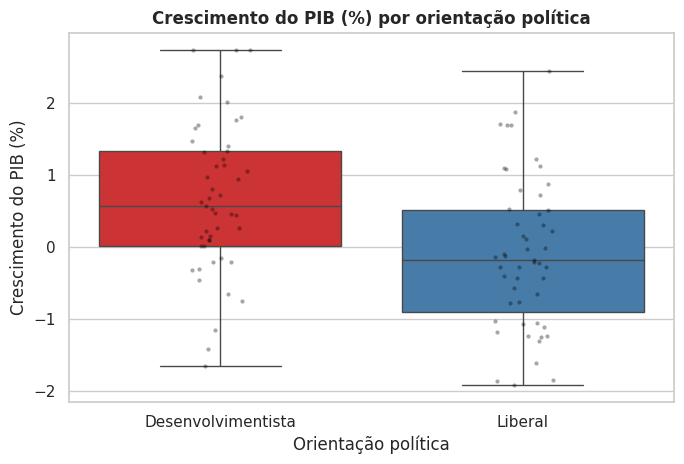

In [11]:
# Gráfico — Crescimento do PIB por orientação política (ilustra Levene e teste t)
plt.figure(figsize=(7, 4.8))
sns.boxplot(data=dados, x="Orientacao_Politica", y="Crescimento_PIB_Pct", hue="Orientacao_Politica",
            palette="Set1", legend=False)
sns.stripplot(data=dados, x="Orientacao_Politica", y="Crescimento_PIB_Pct", color="black", alpha=.35, size=3)
plt.title("Crescimento do PIB (%) por orientação política", fontweight="bold")
plt.xlabel("Orientação política"); plt.ylabel("Crescimento do PIB (%)")
plt.tight_layout()
plt.show()

### 6.2 Mann–Whitney U para inflação e confiança do consumidor

A base fornecida não traz a variável `Meta_Inflacao_Cumprida`. Como a inflação é assimétrica e rejeita normalidade (Shapiro–Wilk), mantemos o teste não paramétrico e comparamos a distribuição da inflação entre dois grupos construídos a partir do índice de confiança do consumidor.

O índice de confiança é ordinal (escala de 1 a 5). Para formar dois grupos de comparação, definimos antecipadamente:

- **Confiança baixa:** índice 1 ou 2.
- **Confiança alta:** índice 4 ou 5.
- Registros com índice 3 ficam fora desta comparação para manter a separação entre os grupos.

**H₀:** as distribuições de inflação nos dois grupos são iguais.  
**H₁:** as distribuições diferem.

O teste de Mann–Whitney é não paramétrico. A interpretação deve considerar o tamanho de cada grupo e não deve afirmar causalidade.


In [12]:
baixa = dados.loc[dados["Indice_Confianca_Consumidor"].isin([1, 2]), "Inflacao_Pct"].dropna()
alta = dados.loc[dados["Indice_Confianca_Consumidor"].isin([4, 5]), "Inflacao_Pct"].dropna()

print(f"Grupo confiança baixa: n={len(baixa)}; mediana da inflação={baixa.median():.3f}")
print(f"Grupo confiança alta: n={len(alta)}; mediana da inflação={alta.median():.3f}")

if len(baixa) > 0 and len(alta) > 0:
    u_stat, u_p = stats.mannwhitneyu(baixa, alta, alternative="two-sided")
    print(f"Mann–Whitney U={u_stat:.4f} | p-valor={u_p:.5f} | decisão={interpretar_p(u_p)}")
else:
    print("Não há observações suficientes nos dois grupos para executar o teste.")


Grupo confiança baixa: n=43; mediana da inflação=4.850
Grupo confiança alta: n=23; mediana da inflação=4.550
Mann–Whitney U=540.5000 | p-valor=0.54032 | decisão=Não rejeitar H₀


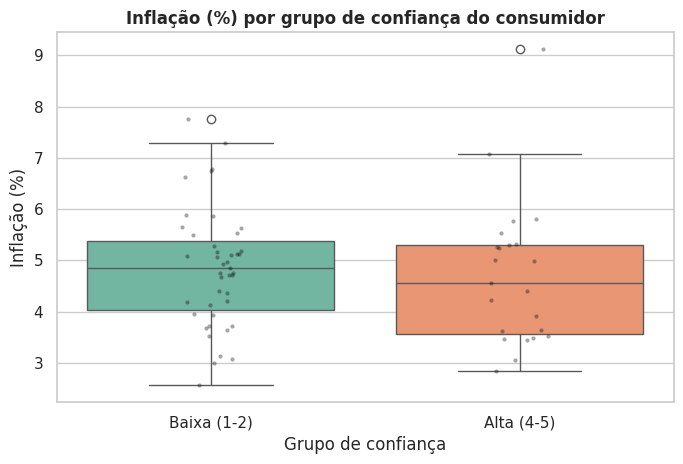

In [13]:
# Gráfico — Inflação por grupo de confiança do consumidor (ilustra o Mann-Whitney)
grupos_conf = dados[dados["Indice_Confianca_Consumidor"].isin([1, 2, 4, 5])].copy()
grupos_conf["Grupo_Confianca"] = np.where(grupos_conf["Indice_Confianca_Consumidor"].isin([1, 2]),
                                          "Baixa (1-2)", "Alta (4-5)")
plt.figure(figsize=(7, 4.8))
sns.boxplot(data=grupos_conf, x="Grupo_Confianca", y="Inflacao_Pct", order=["Baixa (1-2)", "Alta (4-5)"],
            hue="Grupo_Confianca", palette="Set2", legend=False)
sns.stripplot(data=grupos_conf, x="Grupo_Confianca", y="Inflacao_Pct", order=["Baixa (1-2)", "Alta (4-5)"],
              color="black", alpha=.35, size=3)
plt.title("Inflação (%) por grupo de confiança do consumidor", fontweight="bold")
plt.xlabel("Grupo de confiança"); plt.ylabel("Inflação (%)")
plt.tight_layout()
plt.show()

## 7. ANOVA de um fator: desemprego por região

- **H₀:** a média da taxa de desemprego é igual em todas as regiões.
- **H₁:** pelo menos uma região possui média diferente.

A ANOVA indica se existe evidência de alguma diferença entre médias. Se o resultado for significativo, análises posteriores (como Tukey) seriam necessárias para identificar quais pares de regiões diferem.


In [14]:
modelo_anova1 = smf.ols("Desemprego_Pct ~ C(Regiao)", data=dados).fit()
tabela_anova1 = anova_lm(modelo_anova1, typ=2)
display(tabela_anova1)
p_anova1 = tabela_anova1.loc["C(Regiao)", "PR(>F)"]
print("Decisão:", interpretar_p(p_anova1))
display(dados.groupby("Regiao")["Desemprego_Pct"].agg(["count", "mean", "std"]).round(3))


,sum_sq,df,F,PR(>F)
C(Regiao),1.202,3.000,0.356,0.785
Residual,108.053,96.000,NaN,NaN


Decisão: Não rejeitar H₀


,count,mean,std
Regiao,,,
Leste,23,11.801,1.058
Norte,29,11.644,1.079
Oeste,24,11.869,1.122
Sul,24,11.927,0.976


## 8. ANOVA de dois fatores com interação

Investigamos se `Regiao`, `Orientacao_Politica` e a interação entre as duas variáveis estão associadas ao investimento estrangeiro.

- **Efeito de região:** diferenças médias entre regiões.
- **Efeito de orientação política:** diferenças médias entre categorias políticas.
- **Interação:** verifica se a diferença associada à orientação política varia conforme a região.

Para o termo de interação, H₀ afirma que não há interação estatisticamente significativa; H₁ afirma que há interação. Interprete os p-valores com cautela se houver poucas observações em alguma combinação de grupos.


In [15]:
modelo_anova2 = smf.ols(
    "Investimento_Estrangeiro_Milhoes ~ C(Regiao) * C(Orientacao_Politica)",
    data=dados
).fit()
tabela_anova2 = anova_lm(modelo_anova2, typ=2)
display(tabela_anova2)

termo_interacao = "C(Regiao):C(Orientacao_Politica)"
if termo_interacao in tabela_anova2.index:
    p_interacao = tabela_anova2.loc[termo_interacao, "PR(>F)"]
    print(f"p-valor da interação = {p_interacao:.5f}")
    print("Decisão para interação:", interpretar_p(p_interacao))
else:
    print("O termo de interação não foi estimável nesta base.")


,sum_sq,df,F,PR(>F)
C(Regiao),"55,572.974",3.000,0.550,0.650
C(Orientacao_Politica),"36,201.245",1.000,1.074,0.303
C(Regiao):C(Orientacao_Politica),"72,956.050",3.000,0.722,0.541
Residual,"3,099,642.598",92.000,NaN,NaN


p-valor da interação = 0.54149
Decisão para interação: Não rejeitar H₀


Médias do investimento estrangeiro (US$ milhões) por célula:

Orientacao_Politica,Desenvolvimentista,Liberal
Regiao,,
Leste,193.853,165.196
Norte,209.236,216.476
Oeste,220.374,211.715
Sul,318.348,186.475


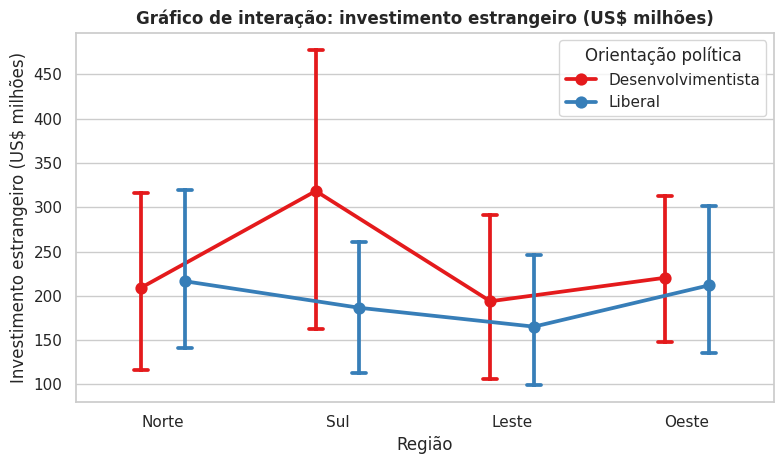

In [16]:
# Médias por célula e gráfico de interação (Região × Orientação política)
print("Médias do investimento estrangeiro (US$ milhões) por célula:")
display(dados.pivot_table(index="Regiao", columns="Orientacao_Politica",
                          values="Investimento_Estrangeiro_Milhoes", aggfunc="mean", observed=True))

plt.figure(figsize=(8, 4.8))
sns.pointplot(data=dados, x="Regiao", y="Investimento_Estrangeiro_Milhoes", hue="Orientacao_Politica",
              order=["Norte", "Sul", "Leste", "Oeste"], dodge=.25, errorbar="ci", capsize=.08, palette="Set1")
plt.title("Gráfico de interação: investimento estrangeiro (US$ milhões)", fontweight="bold")
plt.xlabel("Região"); plt.ylabel("Investimento estrangeiro (US$ milhões)")
plt.legend(title="Orientação política")
plt.tight_layout()
plt.show()

## 9. Regressão linear simples: PIB e desemprego

Ajustamos o modelo:

\[
Desemprego_i = \beta_0 + \beta_1 CrescimentoPIB_i + \varepsilon_i
\]

- **H₀ para β₁:** o coeficiente do crescimento do PIB é igual a zero.
- **H₁ para β₁:** o coeficiente é diferente de zero.

O coeficiente β₁ representa a variação média estimada no desemprego para cada aumento de uma unidade percentual no crescimento do PIB, dentro do modelo. R² representa a proporção da variabilidade da resposta explicada pelo modelo na amostra. Isso não estabelece causalidade.


In [17]:
modelo_simples = smf.ols(
    "Desemprego_Pct ~ Crescimento_PIB_Pct", data=dados
).fit()
print(modelo_simples.summary())

beta0 = modelo_simples.params.get("Intercept", np.nan)
beta1 = modelo_simples.params.get("Crescimento_PIB_Pct", np.nan)
print(f"Equação estimada: Desemprego = {beta0:.4f} + ({beta1:.4f} × Crescimento do PIB)")
print(f"R² = {modelo_simples.rsquared:.4f}")
print(f"p-valor do coeficiente do PIB = {modelo_simples.pvalues.get('Crescimento_PIB_Pct', np.nan):.5f}")


                            OLS Regression Results                            
Dep. Variable:         Desemprego_Pct   R-squared:                       0.754
Model:                            OLS   Adj. R-squared:                  0.751
Method:                 Least Squares   F-statistic:                     299.8
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           1.42e-31
Time:                        21:44:11   Log-Likelihood:                -76.273
No. Observations:                 100   AIC:                             156.5
Df Residuals:                      98   BIC:                             161.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              12.0380    

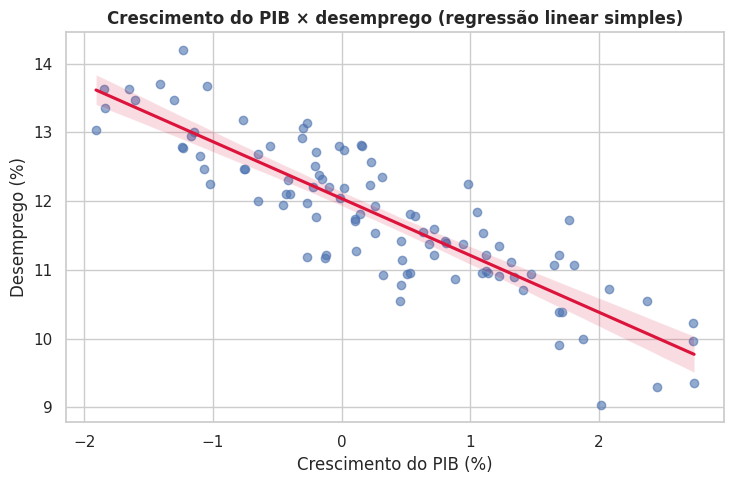

In [18]:
# Gráfico — Dispersão com reta ajustada: PIB × Desemprego
plt.figure(figsize=(7.5, 5))
sns.regplot(data=dados, x="Crescimento_PIB_Pct", y="Desemprego_Pct",
            scatter_kws={"alpha": .6}, line_kws={"color": "crimson"})
plt.title("Crescimento do PIB × desemprego (regressão linear simples)", fontweight="bold")
plt.xlabel("Crescimento do PIB (%)"); plt.ylabel("Desemprego (%)")
plt.tight_layout()
plt.show()

## 10. Regressão linear múltipla: investimento estrangeiro

Modelo proposto:

\[
Investimento_i = \beta_0 + \beta_1 PIB_i + \beta_2 Inflacao_i +
\beta_3 Juros_i + \beta_4 Desemprego_i + \varepsilon_i
\]

Avaliamos os coeficientes individuais por testes t, o teste F global, o R² ajustado e a multicolinearidade por VIF. A significância estatística não garante relevância prática nem capacidade de previsão fora da amostra.


In [19]:
formula_multipla = (
    "Investimento_Estrangeiro_Milhoes ~ Crescimento_PIB_Pct + Inflacao_Pct + "
    "Taxa_Juros_Selic + Desemprego_Pct"
)
modelo_multiplo = smf.ols(formula_multipla, data=dados).fit()
print(modelo_multiplo.summary())

print("\nEquação estimada:")
print(f"Investimento = {modelo_multiplo.params['Intercept']:.4f}")
for variavel in ["Crescimento_PIB_Pct", "Inflacao_Pct", "Taxa_Juros_Selic", "Desemprego_Pct"]:
    coef = modelo_multiplo.params[variavel]
    sinal = "+" if coef >= 0 else "-"
    print(f"  {sinal} {abs(coef):.4f} × {variavel}")

print(f"R² = {modelo_multiplo.rsquared:.4f}")
print(f"R² ajustado = {modelo_multiplo.rsquared_adj:.4f}")
print(f"p-valor do teste F global = {modelo_multiplo.f_pvalue:.5f}")

tabela_coeficientes = pd.DataFrame({
    "Coeficiente": modelo_multiplo.params,
    "Erro padrão": modelo_multiplo.bse,
    "Estatística t": modelo_multiplo.tvalues,
    "p-valor": modelo_multiplo.pvalues
})
tabela_coeficientes["Significativo a 5%"] = tabela_coeficientes["p-valor"] < ALFA
display(tabela_coeficientes.round(5))


                                   OLS Regression Results                                   
Dep. Variable:     Investimento_Estrangeiro_Milhoes   R-squared:                       0.043
Model:                                          OLS   Adj. R-squared:                  0.002
Method:                               Least Squares   F-statistic:                     1.061
Date:                              Tue, 20 Oct 2026   Prob (F-statistic):              0.380
Time:                                      21:44:11   Log-Likelihood:                -659.36
No. Observations:                               100   AIC:                             1329.
Df Residuals:                                    95   BIC:                             1342.
Df Model:                                         4                                         
Covariance Type:                          nonrobust                                         
                          coef    std err          t      P>|t|      [

,Coeficiente,Erro padrão,Estatística t,p-valor,Significativo a 5%
Intercept,-45.783,449.977,-0.102,0.919,False
Crescimento_PIB_Pct,46.104,36.625,1.259,0.211,False
Inflacao_Pct,-14.522,15.475,-0.938,0.350,False
Taxa_Juros_Selic,21.468,12.577,1.707,0.091,False
Desemprego_Pct,11.955,35.052,0.341,0.734,False


### 10.1 Diagnóstico de multicolinearidade (VIF)

O VIF indica quanto a variância estimada de um coeficiente pode estar inflada pela relação linear entre variáveis explicativas. VIF elevado é um alerta para investigar redundância entre preditores; não deve ser interpretado isoladamente como prova de que o modelo é inválido.


In [20]:
X = dados[
    ["Crescimento_PIB_Pct", "Inflacao_Pct", "Taxa_Juros_Selic", "Desemprego_Pct"]
].dropna()
X_const = sm.add_constant(X)

vif = pd.DataFrame({
    "Variável": X_const.columns,
    "VIF": [
        variance_inflation_factor(X_const.values, i)
        for i in range(X_const.shape[1])
    ]
})
display(vif.round(3))


,Variável,VIF
0,const,615.780
1,Crescimento_PIB_Pct,4.907
2,Inflacao_Pct,1.050
3,Taxa_Juros_Selic,1.662
4,Desemprego_Pct,4.082


## 11. Diagnóstico visual do modelo múltiplo

Os gráficos abaixo permitem verificar resíduos e valores ajustados. Idealmente, os resíduos não devem apresentar padrão sistemático e sua dispersão deve ser aproximadamente constante. Este diagnóstico é complementar aos testes e ao conhecimento do contexto.


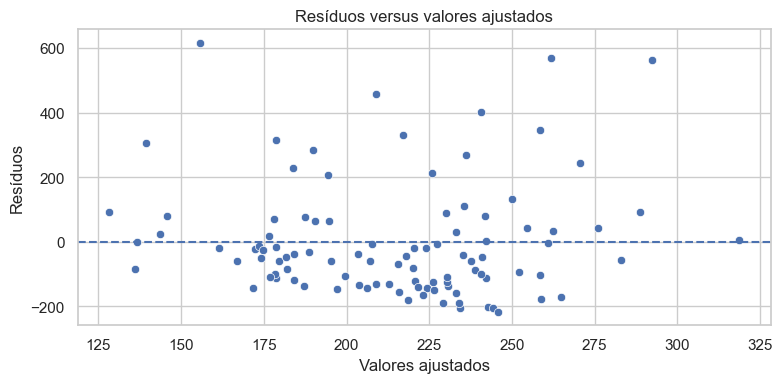

<Figure size 700x400 with 0 Axes>

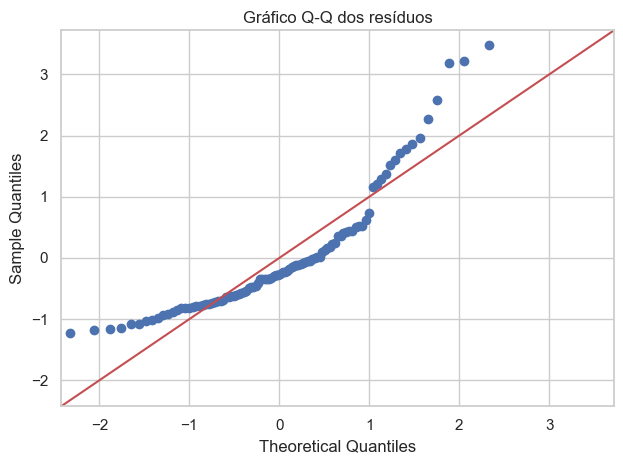

In [21]:
ajustados = modelo_multiplo.fittedvalues
residuos = modelo_multiplo.resid

plt.figure(figsize=(8, 4))
sns.scatterplot(x=ajustados, y=residuos)
plt.axhline(0, linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Resíduos versus valores ajustados")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sm.qqplot(residuos, line="45", fit=True)
plt.title("Gráfico Q-Q dos resíduos")
plt.tight_layout()
plt.show()


## 12. Síntese automática dos principais resultados

Esta célula reúne números centrais para facilitar a redação do relatório. Ela não substitui a interpretação crítica dos gráficos, hipóteses e limitações.


In [22]:
print("=== RESUMO DOS MODELOS ===")
print(f"Observações utilizadas na análise: {len(dados)}")
print(f"Regiões: {', '.join(sorted(dados['Regiao'].astype(str).unique()))}")
print(f"Orientações políticas: {', '.join(sorted(dados['Orientacao_Politica'].astype(str).unique()))}")
print(f"Regressão simples — coeficiente PIB: {modelo_simples.params.get('Crescimento_PIB_Pct', np.nan):.4f}; "
      f"R²: {modelo_simples.rsquared:.4f}; p: {modelo_simples.pvalues.get('Crescimento_PIB_Pct', np.nan):.5f}")
print(f"Regressão múltipla — R² ajustado: {modelo_multiplo.rsquared_adj:.4f}; "
      f"p do teste F: {modelo_multiplo.f_pvalue:.5f}")
print("\nCoeficientes da regressão múltipla:")
display(tabela_coeficientes.round(4))


=== RESUMO DOS MODELOS ===
Observações utilizadas na análise: 100
Regiões: Leste, Norte, Oeste, Sul
Orientações políticas: Desenvolvimentista, Liberal
Regressão simples — coeficiente PIB: -0.8274; R²: 0.7536; p: 0.00000
Regressão múltipla — R² ajustado: 0.0025; p do teste F: 0.38027

Coeficientes da regressão múltipla:


,Coeficiente,Erro padrão,Estatística t,p-valor,Significativo a 5%
Intercept,-45.783,449.977,-0.102,0.919,False
Crescimento_PIB_Pct,46.104,36.625,1.259,0.211,False
Inflacao_Pct,-14.522,15.475,-0.938,0.350,False
Taxa_Juros_Selic,21.468,12.577,1.707,0.091,False
Desemprego_Pct,11.955,35.052,0.341,0.734,False


## 13. Informe executivo — storytelling com dados

**Para:** Ministro da Economia da República de Valória
**De:** Analista Estatístico, Banco Central de Valória
**Assunto:** Diagnóstico estatístico dos indicadores macroeconômicos nacionais (2000–2024)


### 13.1 Introdução executiva

O Conselho de Política Econômica pediu um diagnóstico rigoroso sobre o comportamento dos indicadores macroeconômicos de Valória. Analisamos 100 registros entre 2000 e 2024, distribuídos pelas regiões Norte, Sul, Leste e Oeste, com seis indicadores: crescimento do PIB, inflação, taxa de juros (Selic), desemprego, investimento estrangeiro direto e índice de confiança do consumidor, além da orientação política vigente (Desenvolvimentista ou Liberal).

O informe responde a quatro perguntas de negócio. Primeiro, os indicadores são estáveis ou mostram tendência ao longo dos anos? Segundo, as regiões e as orientações políticas diferem de forma relevante? Terceiro, o que explica o desemprego e o investimento estrangeiro? Quarto, que decisões as evidências sustentam? Todas as conclusões usam nível de significância de 5% e os p-valores produzidos neste notebook.


### 13.2 Diagnóstico de estabilidade e tendências

O crescimento do PIB é modesto e relativamente estável: média de 0,29% e desvio-padrão de 1,10 ponto percentual, com distribuição praticamente simétrica (assimetria 0,17) e compatível com a normalidade (Shapiro–Wilk: W = 0,986, p = 0,358). O desemprego também é estável, com média de 11,8% e desvio-padrão de 1,05 ponto percentual. A inflação tem média de 4,63% e é assimétrica à direita (assimetria 0,60), com alguns registros bem acima da mediana de 4,72%; o Shapiro–Wilk rejeita a normalidade (W = 0,969, p = 0,019), o que justifica o uso de um teste não paramétrico para ela.

O indicador mais volátil é o investimento estrangeiro. Sua média (US$ 214 milhões) é bem maior que a mediana (US$ 152,7 milhões), o desvio-padrão (US$ 181,6 milhões) é próximo da própria média e a assimetria é a maior do conjunto (1,66). Na prática, poucos registros de entrada muito forte de capital puxam a média para cima, e o investimento típico é menor do que a média sugere.

Não encontramos tendência temporal em nenhum indicador: as correlações com o ano ficam entre -0,10 e 0,08, todas com p-valor acima de 0,31, portanto não rejeitamos a hipótese de ausência de tendência (isso indica que não há tendência detectável nesta amostra, não que ela seja comprovadamente nula). A composição regional da amostra é equilibrada (Leste 23, Norte 29, Oeste 24, Sul 24 observações): o qui-quadrado de aderência (χ² = 0,88, p = 0,830) não rejeita a distribuição uniforme.

O mapa de correlações mostra a relação mais forte do estudo: crescimento do PIB e desemprego caminham em sentidos opostos (r = -0,87). O PIB também se correlaciona negativamente com a taxa de juros (r = -0,63), um ponto que reaparece na análise de multicolinearidade.


### 13.3 Validação das políticas públicas

**Orientação política e crescimento.** O teste de Levene indica que a variabilidade do crescimento do PIB é semelhante nas duas orientações (estatística = 0,011, p = 0,918). Com variâncias comparáveis, o teste t de Student mostra diferença estatisticamente significativa nas médias (t = 3,65, 98 graus de liberdade, p = 0,0004): o crescimento médio nos registros Desenvolvimentistas foi de 0,67%, contra -0,09% nos Liberais, uma diferença de cerca de 0,76 ponto percentual e de tamanho moderado a grande (d de Cohen ≈ 0,73). Trata-se de uma associação observada, sem desenho que permita afirmar que a orientação política causou o maior crescimento.

**Inflação e confiança do consumidor.** Como a inflação é assimétrica, usamos o teste de Mann–Whitney. Comparando registros de confiança baixa (índice 1 ou 2; n = 43; mediana de inflação 4,85%) com registros de confiança alta (índice 4 ou 5; n = 23; mediana 4,55%), não há diferença significativa (U = 540,5, p = 0,540). A inflação, nesta base, não distingue os dois grupos de confiança. A ausência de significância pode refletir falta de poder estatístico com grupos pequenos e não prova que as distribuições sejam iguais.

**Desemprego por região.** A ANOVA de um fator não encontra diferença entre as regiões (F = 0,356, p = 0,785); as médias regionais ficam todas entre 11,6% e 11,9%. Como a hipótese nula não foi rejeitada, comparações post hoc de Tukey não se justificam.

**Investimento estrangeiro por região e orientação política.** Na ANOVA de dois fatores, nem a região (F = 0,550, p = 0,650), nem a orientação política (F = 1,074, p = 0,303), nem a interação entre elas (F = 0,722, p = 0,541) são significativas. Ou seja, não há evidência de que o efeito da orientação política sobre o investimento mude de uma região para outra, nem de que as regiões ou as orientações, isoladamente, atraiam volumes distintos de capital. O investimento, que é muito disperso, não é explicado por essas categorias.


### 13.4 Modelo preditivo econométrico e recomendações

**Desemprego e crescimento (regressão simples).** O ajuste é forte e estatisticamente inequívoco:

Desemprego = 12,038 − 0,827 × Crescimento do PIB

Cada ponto percentual adicional de crescimento está associado a uma queda média de 0,83 ponto percentual no desemprego (IC 95%: -0,92 a -0,73; p < 0,001). O modelo explica 75,4% da variação do desemprego (R² = 0,754; teste F global = 299,8; p = 1,4 × 10⁻³¹).

**Investimento estrangeiro (regressão múltipla).** O modelo ajustado é:

Investimento = −45,78 + 46,10 × PIB − 14,52 × Inflação + 21,47 × Juros + 11,96 × Desemprego

Ele não se sustenta: o teste F global não é significativo (F = 1,061; p = 0,380), o R² é 0,043 e o R² ajustado é apenas 0,002. Nenhum coeficiente é significativo a 5% (PIB, p = 0,211; inflação, p = 0,350; juros, p = 0,091; desemprego, p = 0,734). Os sinais dos coeficientes não devem ser interpretados, pois os intervalos de confiança incluem zero. Os VIFs (PIB 4,91; desemprego 4,08; juros 1,66; inflação 1,05) ficam abaixo do limite usual de 10, mas os de PIB e desemprego são os mais altos, o que reflete a forte correlação entre eles; isso não é a causa do mau ajuste, já que o modelo, como um todo, quase não explica o investimento.

**Recomendações, proporcionais às evidências.**
1. *Crescimento é o principal canal para reduzir o desemprego.* A relação entre PIB e desemprego é forte e consistente; políticas que sustentem o crescimento tendem a vir acompanhadas de menor desemprego. Cabe monitorar esse par de indicadores.
2. *A orientação Desenvolvimentista coincidiu com maior crescimento*, mas, por ser dado observacional, recomenda-se avaliar a política com um desenho que permita isolar seu efeito antes de qualquer mudança de rumo.
3. *Não usar este modelo para prever o investimento estrangeiro.* Nenhum dos indicadores macroeconômicos incluídos o explica; vale investigar outros determinantes (risco-país, câmbio, ambiente regulatório) e usar dados de mais variáveis.
4. *Não há base estatística para políticas regionais diferenciadas* em desemprego ou investimento, já que as regiões não diferem de forma detectável.


### 13.5 Limitações

Valória é um país fictício e a base é simulada: os resultados descrevem apenas este conjunto de dados e servem como exercício metodológico, não como fundamento de decisões econômicas reais. Todas as relações são associações, não causalidade. Resultados não significativos indicam ausência de evidência detectável com 100 observações, não ausência de efeito. A base fornecida não contém `Periodo_Politica` nem `Meta_Inflacao_Cumprida`; as comparações correspondentes foram adaptadas para `Orientacao_Politica` e para os grupos de confiança do consumidor. Os modelos não foram validados fora da amostra.
